# 02 · Measuring the variance risk premium (Tier 1)

**Owner: Nahid**

**Question:** is implied variance (VIX²) higher than the variance that actually follows, on average? If it is, how large is the premium, is it statistically significant, and what do its losses look like?

`vrp` = VIX²/10000 − realized variance over the next 21 trading days. It is the P&L of a short variance swap per unit notional.

In [3]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import load_daily, EPISODES, episode_mask
df = load_daily('../data/daily.csv')
df.tail()

,spx_open,spx_high,spx_low,spx_close,vix,vix3m,rf,logret,iv_var,rv_d,rv_w,rv_m,rv_parkinson_d,rv_fwd21,vrp,vrp_volpts,vix_ratio
date,,,,,,,,,,,,,,,,,
2026-10-26,7639.700195,7702.129883,7639.700195,7676.770020,18.389999,19.940001,0.0405,0.006940,0.033819,0.012136,0.013321,0.009624,0.006020,NaN,NaN,NaN,0.922267
2026-10-27,7699.470215,7736.240234,7677.160156,7722.600098,17.520000,19.570000,0.0405,0.005952,0.030695,0.008928,0.014701,0.009330,0.005342,NaN,NaN,NaN,0.895248
2026-10-28,7735.560059,7758.430176,7718.370117,7743.979980,16.910000,19.219999,0.0401,0.002765,0.028595,0.001926,0.013411,0.009388,0.002436,NaN,NaN,NaN,0.879813
2026-10-29,7699.609863,7732.209961,7690.939941,7720.390137,17.200001,19.370001,0.0400,-0.003051,0.029584,0.002346,0.006430,0.009423,0.002603,NaN,NaN,NaN,0.887971
2026-10-30,7631.069824,7637.479980,7527.560059,7580.069824,19.420000,20.780001,0.0400,-0.018342,0.037714,0.084785,0.022024,0.013415,0.019101,NaN,NaN,NaN,0.934552


## 1. Plot
Two panels: (a) VIX² and RV together, (b) `vrp` over time. Shade `EPISODES`.

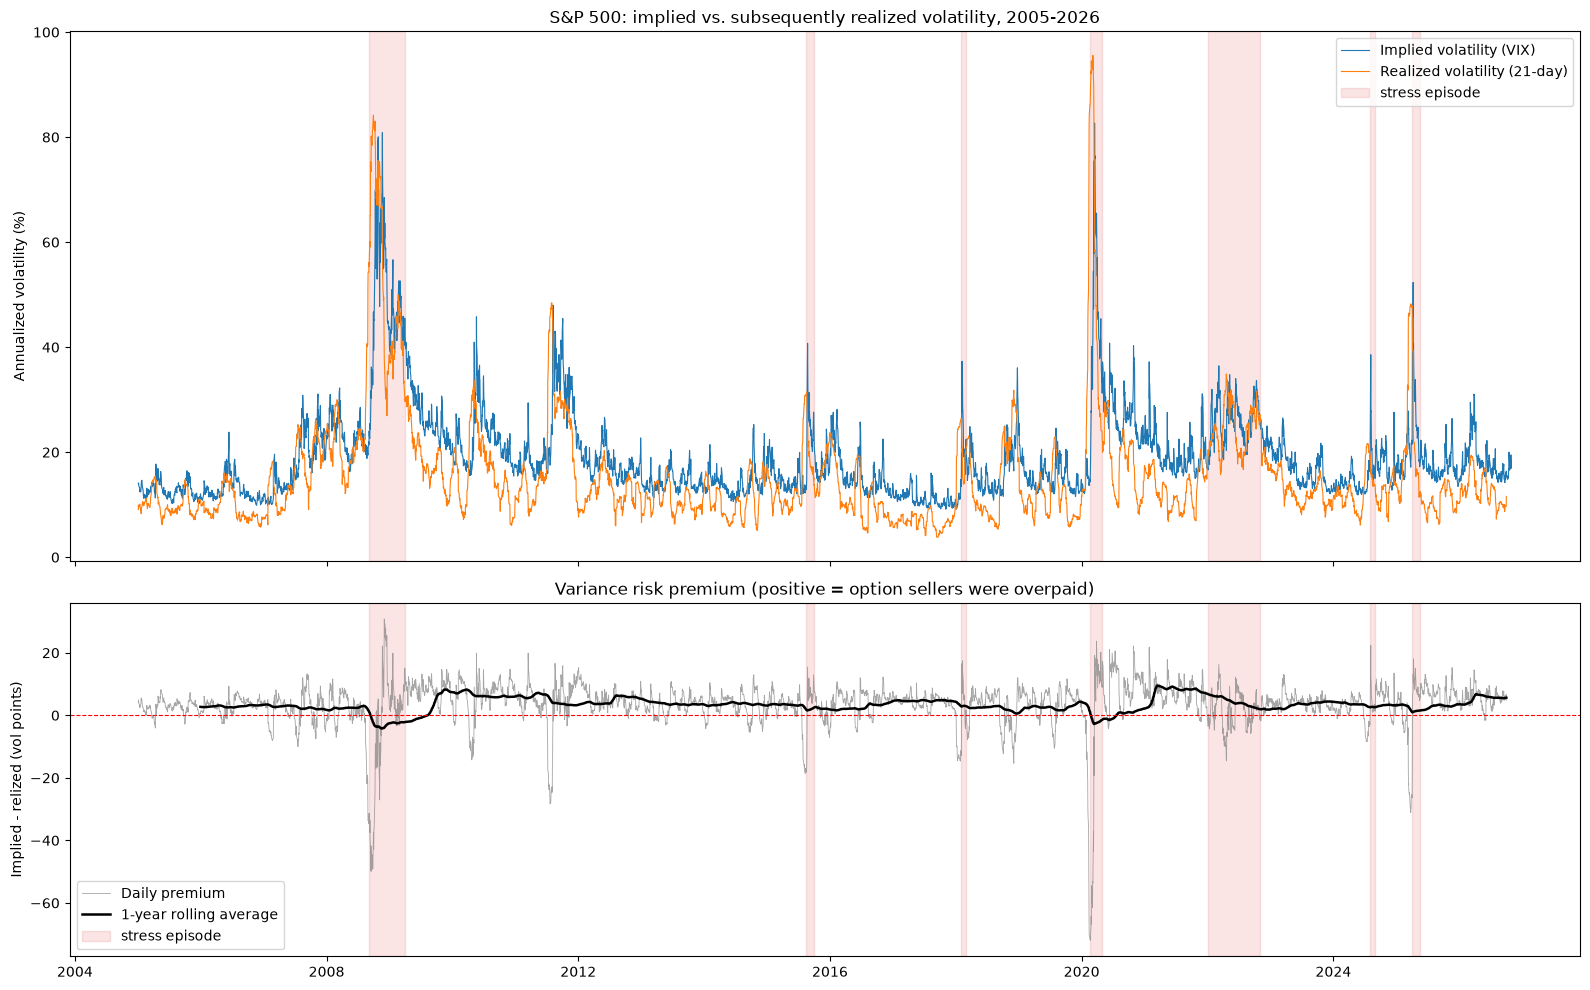

In [10]:
import os
os.makedirs('../docs/figures', exist_ok=True)

impl_vol = 100 * np.sqrt(df["iv_var"]) # VIX, in volatility points
real_vol = 100 * np.sqrt(df["rv_fwd21"]) # realized volatility, in volatility points over the next 21 days
vrp_pts = df["vrp_volpts"] # implied minus realized volatility, in volatility points

fig, (ax1, ax2) = plt.subplots(2, 1, sharex = True, figsize = (16, 10), gridspec_kw = {"height_ratios": [3, 2]})

# (a) implied vs realized volatility
ax1.plot(impl_vol.index, impl_vol, lw = 0.8, color = "tab:blue", label = "Implied volatility (VIX)")
ax1.plot(real_vol.index, real_vol, lw = 0.8, color = "tab:orange", label = "Realized volatility (21-day)")
ax1.set_ylabel("Annualized volatility (%)")
ax1.set_title("S&P 500: implied vs. subsequently realized volatility, 2005-2026")

# the premium
ax2.plot(vrp_pts.index, vrp_pts, lw = 0.6, color = "grey", alpha = 0.7, label = "Daily premium")
ax2.plot(vrp_pts.index, vrp_pts.rolling(252).mean(), lw = 1.8, color = "black", label = "1-year rolling average")
ax2.axhline(0, color = "red", lw = 0.8, ls = "--")
ax2.set_ylabel("Implied - relized (vol points)")
ax2.set_title("Variance risk premium (positive = option sellers were overpaid)")

# shade crisis episodes on both panels, labelling each once
for ax in (ax1, ax2):
    for i, (name, (s, e)) in enumerate(EPISODES.items()):
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color = "tab:red", alpha = 0.12, label = "stress episode" if i == 0 else None)
ax1.legend(loc = "upper right")
ax2.legend(loc = "lower left")

plt.tight_layout()
plt.savefig
plt.show()

## 2. Is the average premium positive?

**(a) Overlapping daily data with Newey–West errors.** Neighbouring days share 20 of 21 returns, so plain standard errors are far too small.

Hint: `import statsmodels.api as sm`, then `sm.OLS(y, np.ones(len(y))).fit(cov_type='HAC', cov_kwds={'maxlags': 21})`. Try maxlags 21, 30 and 42, and report whether the conclusion changes.

**(b) Non-overlapping months.** Take every 21st row (`y.iloc[::21]`) and run a plain one-sample t-test (`scipy.stats.ttest_1samp`).

In [ ]:
y = df['vrp'].dropna()
# TODO (a) Newey-West


In [ ]:
# TODO (b) non-overlapping t-test


## 3. Shape of the payoff
Mean, median, share of months positive, skewness, kurtosis, 5% CVaR (mean of the worst 5% of months) and the 5 worst months, all on the non-overlapping sample. Add a histogram.

Expected story: small gains most months, rare very large losses.

In [ ]:
# TODO

## 4. Episode table
For each entry in `EPISODES`: peak VIX, average realized vol, worst `vrp`, and the cumulative short-variance P&L over the episode.

Note on 2022: stocks fell but VIX stayed contained, so it should look much milder than 2008, Feb 2018, 2020 or Apr 2025.

In [ ]:
rows = []
for name in EPISODES:
    m = episode_mask(df.index, name)
    # TODO: compute the statistics for df[m]


## 5. Takeaways for the executive summary
Write 3 bullet points in plain English.